# 05. 텍스트 요약 오류 분석

이 노트북에서는 Text Modality만 검증한다. 이미지 요약은 텍스트와 같은 기준으로 감성 반전이나 정보 누락을 판정하기 어려워 이번 분석에서 제외한다.

본 분석은 원본 리뷰와 LLaMA 요약문에서 추출된 속성별 감성 방향을 비교하여, 요약 과정에서 발생하는 감성 반전과 부정 속성 누락이 추천 성능과 어떠한 관련성을 가지는지 확인하는 데 목적이 있다. 이를 통해 요약문이 사용자의 선호와 불만 정보를 충실하게 보존하는지를 정량적으로 검토한다.

또한 요약문에만 나타난 속성을 별도로 식별하여, 요약 과정에서 추가된 정보가 추천 성능과 어떠한 관계를 가지는지 분석한다. 자동 분석은 잠재적 오류 사례를 선별하는 데 사용하며, 환각 여부는 원문과 요약문을 직접 비교하여 최종 판정한다.

In [16]:
# Colab에서 한 번만 실행
# PyABSA는 update-checker 1.x와 호환되지 않아 0.18.0으로 고정
%pip install -q -U pyabsa "transformers<5" accelerate "update-checker==0.18.0"

# 설치가 끝나면 런타임을 다시 시작하고 다음 셀부터 실행

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
# 데이터 처리 및 시각화
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# PyABSA 속성 추출 모델
from pyabsa import AspectTermExtraction as ATEPC

sns.set_theme(
    style='white',
    context='notebook',
    font_scale=1.05,
    rc={
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'savefig.facecolor': 'white'
    }
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[2026-11-23 04:59:12] (2.4.2) PyABSA(2.4.2): If your code crashes on Colab, please use the GPU runtime. Then run "pip install pyabsa[dev] -U" and restart the kernel.
Or if it does not work, you can use v1.x versions, e.g., pip install pyabsa<2.0 -U




Try to downgrade transformers<=4.29.0.






/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Utils

In [19]:
def clean_aspects(aspects):
    cleaned = []

    for aspect in aspects:
        aspect = re.sub(r'\s+', ' ', str(aspect).strip().lower())

        if aspect and aspect not in cleaned:
            cleaned.append(aspect)

    return cleaned

In [20]:
def make_keyword_pattern(keyword):
    # 단수형 키워드와 자주 나타나는 복수형을 같은 표현으로 처리
    variants = {keyword}

    if keyword.endswith('y') and len(keyword) > 1 and keyword[-2] not in 'aeiou':
        variants.add(f'{keyword[:-1]}ies')
    elif keyword.endswith(('s', 'x', 'z', 'ch', 'sh')):
        variants.add(f'{keyword}es')
    else:
        variants.add(f'{keyword}s')

    return rf"\b(?:{'|'.join(re.escape(value) for value in variants)})\b"

In [21]:
def normalize_aspect(aspect):
    # JSON에 정의된 동의어와 형태 변형을 대표 속성명으로 통합
    for category, rule in aspect_rules.items():
        for keyword in rule['keywords']:
            if re.search(make_keyword_pattern(keyword), aspect):
                aspect_type = (
                    'Paper aspect'
                    if rule['predefined']
                    else 'Derived aspect'
                )
                return category, rule['predefined'], aspect_type

    return aspect, False, 'Additional aspect'

In [22]:
def make_aspect_map(aspects, sentiments, confidences):
    aspect_map = {}

    for index, raw_aspect in enumerate(aspects):
        raw_aspect = re.sub(
            r'\s+', ' ', str(raw_aspect).strip().lower()
        )

        if not raw_aspect:
            continue

        aspect, predefined, aspect_type = normalize_aspect(raw_aspect)
        sentiment = sentiments[index] if index < len(sentiments) else None
        confidence = (
            float(confidences[index])
            if index < len(confidences)
            else np.nan
        )

        current = aspect_map.get(aspect)
        current_confidence = (
            current['confidence'] if current else -np.inf
        )

        # 같은 범주가 여러 번 나오면 신뢰도가 가장 높은 결과를 사용
        if current is None or confidence > current_confidence:
            aspect_map[aspect] = {
                'raw_aspect': raw_aspect,
                'predefined': predefined,
                'aspect_type': aspect_type,
                'sentiment': sentiment,
                'confidence': confidence
            }

    return aspect_map

In [23]:
# PyABSA 감성 라벨을 분석용 숫자로 변환
def sentiment_to_score(sentiment):
    score_map = {
        'negative': -1,
        'neutral': 0,
        'positive': 1
    }

    return score_map.get(str(sentiment).lower(), np.nan)

## 원본 리뷰와 예측 결과 연결

03 노트북에서 저장한 `source_index`를 이용해 Test 예측 결과에 원본 리뷰를 연결한다.

In [27]:
# 원본 데이터와 Test 예측 결과 불러오기
# 원본 데이터와 Test 예측 결과 불러오기
data_path = (
    '/content/drive/MyDrive/Dataset/Amazon_Dataset/MAS-Rec/'
    'Clothing and Shoes/03_LLM_Outputs/Aspect/Final/'
    'Clothing_Shoes_aspect_final.pkl'
)

prediction_path = (
    '/content/drive/MyDrive/MAS_Rec/03_Predictions/'
    'MAS_Rec_test_predictions.pkl'
)

df = pd.read_pickle(data_path)
prediction_df = pd.read_pickle(prediction_path)

text_error_df = prediction_df.copy()
text_error_df['text'] = df.loc[text_error_df['source_index'], 'text'].to_numpy()

data_summary = pd.DataFrame({
    'data': ['Original data', 'Test predictions', 'Matched reviews'],
    'count': [len(df), len(prediction_df), text_error_df['text'].notna().sum()]
})

data_summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,data,count
0,Original data,66718
1,Test predictions,13344
2,Matched reviews,13344


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


원본 행 번호를 사용하므로 Test 예측 결과와 해당 리뷰를 같은 순서로 정확히 연결할 수 있다.

In [28]:
# None이면 전체 Test 데이터를 사용
# 처음 확인할 때만 100처럼 작은 값을 사용
MAX_ROWS = None

if MAX_ROWS is None:
    analysis_df = text_error_df.copy()
    analysis_name = 'full_test'
else:
    analysis_df = text_error_df.sample(
        n=min(MAX_ROWS, len(text_error_df)),
        random_state=42
    ).sort_values('source_index').copy()
    analysis_name = f'sample_{len(analysis_df)}'

analysis_df[['rating', 'prediction', 'absolute_error']].describe().round(4)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rating,prediction,absolute_error
count,13344.0000,13344.0000,13344.0000
mean,4.5891,4.6516,0.3278
std,0.7315,0.6454,0.3987
min,1.0000,1.0543,0.0000
25%,4.0000,4.4565,0.0692
50%,5.0000,4.9297,0.1477
75%,5.0000,5.0653,0.4753
max,5.0000,5.2911,3.7074


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


분석 데이터의 평점과 오차 범위를 먼저 확인한 뒤 속성 추출을 진행한다.

## PyABSA 속성 추출

PyABSA를 사용해 원본 리뷰와 요약문에서 속성어를 각각 추출한다.
PyABSA가 속성어와 감성, 신뢰도를 함께 출력하므로 이후 분석에서도 이 결과를 그대로 사용한다.

In [29]:
aspect_extractor = ATEPC.AspectExtractor(
    'multilingual',
    auto_device=True,
    cal_perplexity=False
)

# 모델이 지원하는 범위에서 최대 입력 길이를 512로 설정
model_max_length = aspect_extractor.bert.config.max_position_embeddings
ASPECT_MAX_LENGTH = min(512, model_max_length)
ASPECT_BATCH_SIZE = 32
EXTRACTION_CHUNK_SIZE = 2000

aspect_extractor.config.max_seq_len = ASPECT_MAX_LENGTH
analysis_tag = f'{analysis_name}_len{ASPECT_MAX_LENGTH}'

aspect_model_setting = pd.DataFrame({
    'setting': [
        'Model max length',
        'Applied max length',
        'Batch size',
        'Checkpoint chunk size'
    ],
    'value': [
        model_max_length,
        ASPECT_MAX_LENGTH,
        ASPECT_BATCH_SIZE,
        EXTRACTION_CHUNK_SIZE
    ]
})

aspect_model_setting

[2026-11-23 05:07:39] (2.4.2) ********** Available ATEPC model checkpoints for Version:2.4.2 (this version) **********
[2026-11-23 05:07:39] (2.4.2) ********** Available ATEPC model checkpoints for Version:2.4.2 (this version) **********
[2026-11-23 05:07:39] (2.4.2) Downloading checkpoint:multilingual 
[2026-11-23 05:07:39] (2.4.2) Notice: The pretrained model are used for testing, it is recommended to train the model on your own custom datasets
[2026-11-23 05:07:39] (2.4.2) Checkpoint already downloaded, skip
[2026-11-23 05:07:40] (2.4.2) Load aspect extractor from checkpoints/ATEPC_MULTILINGUAL_CHECKPOINT
[2026-11-23 05:07:40] (2.4.2) config: checkpoints/ATEPC_MULTILINGUAL_CHECKPOINT/fast_lcf_atepc.config
[2026-11-23 05:07:40] (2.4.2) state_dict: checkpoints/ATEPC_MULTILINGUAL_CHECKPOINT/fast_lcf_atepc.state_dict
[2026-11-23 05:07:40] (2.4.2) model: None
[2026-11-23 05:07:40] (2.4.2) tokenizer: checkpoints/ATEPC_MULTILINGUAL_CHECKPOINT/fast_lcf_atepc.tokenizer
[2026-11-23 05:07:40] 

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


,setting,value
0,Model max length,512
1,Applied max length,512
2,Batch size,32
3,Checkpoint chunk size,2000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


예시 문장에서 `fit`, `material`, `color`, `shoes`와 같은 속성이 추출되는지 확인한다.

In [ ]:
# 원본 리뷰와 LLaMA 요약문의 속성 추출
aspect_cache_path = Path(
    f'/content/drive/MyDrive/MAS_Rec/text_aspects_{analysis_tag}.pkl'
)

cache_is_valid = False
required_columns = {
    'source_index',
    'review_aspects', 'review_sentiments', 'review_confidences',
    'summary_aspects', 'summary_sentiments', 'summary_confidences'
}

# 저장된 결과가 현재 분석 데이터와 같은 크기인지 확인
if aspect_cache_path.exists():
    aspect_result_df = pd.read_pickle(aspect_cache_path)
    cache_is_valid = (
        len(aspect_result_df) == len(analysis_df)
        and required_columns.issubset(aspect_result_df.columns)
        and aspect_result_df['source_index'].reset_index(drop=True).equals(
            analysis_df['source_index'].reset_index(drop=True)
        )
    )

if not cache_is_valid:
    aspect_chunk_dir = Path(
        f'/content/drive/MyDrive/MAS_Rec/aspect_chunks/{analysis_tag}'
    )
    aspect_chunk_dir.mkdir(parents=True, exist_ok=True)
    chunk_frames = []

    for start in range(0, len(analysis_df), EXTRACTION_CHUNK_SIZE):
        end = min(start + EXTRACTION_CHUNK_SIZE, len(analysis_df))
        chunk_path = aspect_chunk_dir / f'chunk_{start:06d}_{end:06d}.pkl'
        chunk_input = analysis_df.iloc[start:end].copy()

        if chunk_path.exists():
            chunk_df = pd.read_pickle(chunk_path)
            chunk_is_valid = (
                len(chunk_df) == len(chunk_input)
                and required_columns.issubset(chunk_df.columns)
                and chunk_df['source_index'].reset_index(drop=True).equals(
                    chunk_input['source_index'].reset_index(drop=True)
                )
            )

            if chunk_is_valid:
                chunk_frames.append(chunk_df)
                print(f'Loaded chunk: {start:,}-{end:,}')
                continue

        review_texts = chunk_input['text'].fillna('').astype(str).tolist()
        summary_texts = chunk_input['LLaMA_Output'].fillna('').astype(str).tolist()

        review_results = aspect_extractor.predict(
            review_texts,
            save_result=False,
            print_result=False,
            pred_sentiment=True,
            ignore_error=True,
            eval_batch_size=ASPECT_BATCH_SIZE
        )
        summary_results = aspect_extractor.predict(
            summary_texts,
            save_result=False,
            print_result=False,
            pred_sentiment=True,
            ignore_error=True,
            eval_batch_size=ASPECT_BATCH_SIZE
        )

        if len(review_results) != len(chunk_input):
            raise ValueError(f'원본 리뷰 결과 개수 오류: {start}-{end}')

        if len(summary_results) != len(chunk_input):
            raise ValueError(f'요약문 결과 개수 오류: {start}-{end}')

        chunk_df = chunk_input[['source_index']].copy()

        chunk_df['review_aspects'] = [result.get('aspect', []) for result in review_results]
        chunk_df['review_sentiments'] = [result.get('sentiment', []) for result in review_results]
        chunk_df['review_confidences'] = [result.get('confidence', []) for result in review_results]
        chunk_df['summary_aspects'] = [result.get('aspect', []) for result in summary_results]
        chunk_df['summary_sentiments'] = [result.get('sentiment', []) for result in summary_results]
        chunk_df['summary_confidences'] = [result.get('confidence', []) for result in summary_results]
        
        chunk_df.to_pickle(chunk_path)
        chunk_frames.append(chunk_df)
        print(f'Saved chunk: {start:,}-{end:,}')

    aspect_result_df = pd.concat(
        chunk_frames,
        ignore_index=True
    )
    aspect_result_df.to_pickle(aspect_cache_path)

aspect_count_summary = pd.DataFrame({
    'text_type': ['Original review', 'LLaMA summary'],
    'mean_aspect_count': [
        aspect_result_df['review_aspects'].apply(clean_aspects).str.len().mean(),
        aspect_result_df['summary_aspects'].apply(clean_aspects).str.len().mean()
    ],
    'no_aspect_count': [
        aspect_result_df['review_aspects'].apply(clean_aspects).str.len().eq(0).sum(),
        aspect_result_df['summary_aspects'].apply(clean_aspects).str.len().eq(0).sum()
    ]
}).round(3)

aspect_count_summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
classifying aspect sentiments: 100%|██████████| 286/286 [11:52<00:00,  2.49s/it]
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Saved chunk: 0-2,000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
classifying aspect sentiments: 100%|██████████| 283/283 [11:44<00:00,  2.49s/it]
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Saved chunk: 2,000-4,000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
classifying aspect sentiments: 100%|██████████| 283/283 [11:39<00:00,  2.47s/it]
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Saved chunk: 4,000-6,000


... (7 outputs left out)

Saved chunk: 12,000-13,344


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text_type,mean_aspect_count,no_aspect_count
0,Original review,2.550,967
1,LLaMA summary,4.341,155


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 추출된 속성 확인

원본 리뷰와 요약문에서 모델이 추출한 속성을 나란히 확인한다. 중복 속성은 실제 분석과 동일하게 제거해 표시한다.

In [ ]:
# 리뷰별로 원문, 요약문, 추출 속성을 한 행에 정리
aspect_inspection_df = analysis_df[[
    'source_index', 'text', 'LLaMA_Output'
]].merge(
    aspect_result_df[[
        'source_index', 'review_aspects', 'summary_aspects'
    ]],
    on='source_index',
    how='left'
)

# 뒤의 분석에서 사용하는 것과 같이 중복 속성을 제거
aspect_inspection_df['review_aspects'] = (
    aspect_inspection_df['review_aspects'].apply(clean_aspects)
)
aspect_inspection_df['summary_aspects'] = (
    aspect_inspection_df['summary_aspects'].apply(clean_aspects)
)

aspect_inspection_df = aspect_inspection_df.rename(columns={
    'text': 'original_review',
    'LLaMA_Output': 'llama_summary',
    'review_aspects': 'original_review_aspects',
    'summary_aspects': 'llama_summary_aspects'
})

# 행 수를 늘리려면 아래 숫자만 변경
ASPECT_PREVIEW_ROWS = 20

with pd.option_context('display.max_colwidth', 120):
    display(aspect_inspection_df.head(ASPECT_PREVIEW_ROWS))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,source_index,original_review,llama_summary,original_review_aspects,llama_summary_aspects
0,63407,I wear size 10 shoe and the large fit fine. These are a thinner sock but still comfortable. I thought the designs we...,"Based on the user's review, it appears that they prefer clothing items with a comfortable fit, specifically mentioni...","[fit, designs, price]","[fit, size, designs]"
1,64144,"Price wise, these were definitely worth it!!<br />I ordered these for a ball and they worked great at complimenting ...","Based on user reviews, it appears that customers are pleased with the value for money of these clothing items, consi...",[],"[value for money, price, design]"
2,18896,These shorts are quite versatile. They go with pretty much everything and are super comfortable. I got a couple of c...,"Based on user reviews, it appears that users prefer versatile clothing items that can be easily paired with various ...","[shorts, jeans]","[clothing items, comfort, shorts, jeans]"
3,38719,This quilted best is a perfect fit. It’s light weight with zipper and snaps. I think it’s perfect with a sweater or ...,"Based on this review, users prefer clothing with a perfect fit, lightweight materials, and functional features such ...","[fit, zipper]","[fit, materials, features, zippers, styling]"
4,29368,Beautiful gold necklace! Subtle elegance that doesn’t go out of style.<br />Nice quality.<br />I’m wearing it on th...,"Based on user reviews, it appears that users prefer jewelry with a touch of elegance and subtlety. They also value q...",[quality],[fit]
5,36384,A great FATHERS DAY gift. a great BIRTHDAY gift.<br />We buy again.,"Based on the user reviews, it appears that the product is a popular choice for special occasions such as Father's Da...",[gift],"[quality, styles, colors, fits, patterns]"
6,13694,This umbrella will be a great add to our home. It has a ton to like so I will try to list it all. The umbrella on th...,"Based on this review, here is a summary of user preferences for clothing, shoes, and jewelry:\n\nThe user prefers cl...","[umbrella, structure, sleeve, handle]","[functionality, structure, design, handle, designs]"
7,48490,This bracelet may be better for larger wrists. I wore it on the shortest link because I have small wrists. About 5.5...,"Based on user reviews, it appears that users prefer bracelets that fit comfortably and securely on their wrists. The...","[crystals, fit, strands]","[fit, weight distribution, crystals, use, materials, craftsmanship, functionality, comfort, aesthetics]"
8,49541,"EXCEEDED MY EXPECTATIONS WITH IT'S MULTI FEATURES, LIGHTING AND READABLE TIME & DATE","Based on user reviews, it appears that users highly value products with multiple features, such as this one, which o...","[multi features, lighting]","[features, lighting, style, designs]"
9,41586,"Design and colors look nice. Material is heavier cotton. Material is soft, but not as much as we like. Wish it was a...","Based on user reviews, it appears that users appreciate the design and colors of the shirt, as well as the soft mate...","[design, colors, material, fit, sleeves, shoulder blades]","[design, colors, material, fit, sleeves, shoulder blades, appearance, size]"


위 표는 각 리뷰에서 검출된 속성이 요약문에서 유지되거나 새로 나타났는지 직접 확인하기 위한 결과이다.

## 속성 정리 및 원문-요약 비교

논문에서 사용한 `style`, `color`, `fit`, `pattern`, `brand`는 사전 정의 속성으로 정리한다.
그 밖의 의미 있는 속성은 삭제하지 않고 추가 속성으로 보존한다.

예를 들어 `style`, `design`, `look`, `appearance`, `fashion`은 모두 `style`로 통합하며, `designs`, `colors`, `materials`와 같은 복수형도 각 대표 속성에 포함한다.

In [32]:
# My Drive와 공유 드라이브에서 규칙 파일 검색
aspect_rules_path = next((path for path in Path('/content/drive').rglob('aspect_rules.json') if path.parent.name == 'configs'), None)

if aspect_rules_path is None:
    raise FileNotFoundError('Drive에서 aspect_rules.json을 찾지 못했습니다.')

with aspect_rules_path.open(encoding='utf-8') as file:
    aspect_rules = json.load(file)

aspect_rule_df = pd.DataFrame([
    {
        'aspect': aspect,
        'keywords': ', '.join(rule['keywords']),
        'type': (
            'Paper aspect'
            if rule['predefined']
            else 'Derived aspect'
        )
    }
    for aspect, rule in aspect_rules.items()
])

print(f'Loaded from: {aspect_rules_path}')
aspect_rule_df

Loaded from: /content/drive/MyDrive/MAS_Rec/configs/aspect_rules.json


,aspect,keywords,type
0,style,"style, design, look, appearance, fashion",Paper aspect
1,color,"color, colour, shade",Paper aspect
2,fit,"fit, size, sizing, length, width",Paper aspect
3,pattern,"pattern, print, graphic",Paper aspect
4,brand,"brand, label, manufacturer",Paper aspect
5,quality,"quality, construction, craftsmanship",Derived aspect
6,comfort,"comfort, comfortable, support, cushion",Derived aspect
7,material,"material, fabric, leather, cotton",Derived aspect
8,durability,"durability, durable, stitching, zipper, sole",Derived aspect
9,value,"value, price, cost, money",Derived aspect


In [58]:
# 원본과 요약문의 속성 보존 여부 정리
aspect_rows = []

for row in aspect_result_df.itertuples(index=False):
    review_map = make_aspect_map(
        row.review_aspects,
        row.review_sentiments,
        row.review_confidences
    )
    summary_map = make_aspect_map(
        row.summary_aspects,
        row.summary_sentiments,
        row.summary_confidences
    )
    aspect_names = sorted(set(review_map) | set(summary_map))

    for aspect in aspect_names:
        in_review = aspect in review_map
        in_summary = aspect in summary_map

        if in_review and in_summary:
            status = 'preserved'
        elif in_review:
            status = 'omitted'
        else:
            status = 'summary_only'

        aspect_rows.append({
            'source_index': row.source_index,
            'aspect': aspect,
            'predefined': review_map.get(aspect, summary_map.get(aspect))['predefined'],
            'aspect_type': review_map.get(aspect, summary_map.get(aspect))['aspect_type'],
            'review_aspect_raw': review_map.get(aspect, {}).get('raw_aspect'),
            'summary_aspect_raw': summary_map.get(aspect, {}).get('raw_aspect'),
            'review_sentiment': review_map.get(aspect, {}).get('sentiment'),
            'review_confidence': review_map.get(aspect, {}).get('confidence'),
            'summary_sentiment': summary_map.get(aspect, {}).get('sentiment'),
            'summary_confidence': summary_map.get(aspect, {}).get('confidence'),
            'status': status
        })

aspect_pair_df = pd.DataFrame(aspect_rows)

aspect_pair_df = aspect_pair_df.merge(
    analysis_df[['source_index', 'rating', 'prediction', 'absolute_error', 'signed_error']],
    on='source_index',
    how='left',
    validate='many_to_one'
)

aspect_status = aspect_pair_df.groupby('status').agg(count=('aspect', 'size'), mean_absolute_error=('absolute_error', 'mean')).round(4)

aspect_status

,count,mean_absolute_error
status,,
omitted,18001,0.3349
preserved,15331,0.3163
summary_only,37700,0.3266


In [ ]:
# 한 리뷰의 같은 속성이 원문과 요약문에서 어떻게 대응되는지 확인
aspect_pair_df.head(10)

,source_index,aspect,predefined,aspect_type,review_aspect_raw,summary_aspect_raw,review_sentiment,review_confidence,summary_sentiment,summary_confidence,...,rating,prediction,absolute_error,signed_error,review_sentiment_score,summary_sentiment_score,sentiment_shift,sentiment_flip,negative_aspect_omitted,summary_only_candidate
0,63407,designs,False,Additional aspect,designs,designs,Positive,0.9778,Positive,0.9848,...,5,4.870286,0.129714,-0.129714,1.0,1.0,0.0,False,False,False
1,63407,fit,True,Paper aspect,fit,size,Positive,0.9456,Positive,0.9953,...,5,4.870286,0.129714,-0.129714,1.0,1.0,0.0,False,False,False
2,63407,value,False,Derived aspect,price,None,Positive,0.9476,None,NaN,...,5,4.870286,0.129714,-0.129714,1.0,NaN,NaN,False,False,False
3,64144,style,True,Paper aspect,None,design,None,NaN,Positive,0.9969,...,5,5.040724,0.040724,0.040724,NaN,1.0,NaN,False,False,True
4,64144,value,False,Derived aspect,None,value for money,None,NaN,Positive,0.9974,...,5,5.040724,0.040724,0.040724,NaN,1.0,NaN,False,False,True
5,18896,clothing items,False,Additional aspect,None,clothing items,None,NaN,Positive,0.9820,...,5,5.064471,0.064471,0.064471,NaN,1.0,NaN,False,False,True
6,18896,comfort,False,Derived aspect,None,comfort,None,NaN,Positive,0.9878,...,5,5.064471,0.064471,0.064471,NaN,1.0,NaN,False,False,True
7,18896,jeans,False,Additional aspect,jeans,jeans,Positive,0.5478,Positive,0.7458,...,5,5.064471,0.064471,0.064471,1.0,1.0,0.0,False,False,False
8,18896,shorts,False,Additional aspect,shorts,shorts,Positive,0.9952,Positive,0.9927,...,5,5.064471,0.064471,0.064471,1.0,1.0,0.0,False,False,False
9,38719,durability,False,Derived aspect,zipper,None,Positive,0.9683,None,NaN,...,5,4.924215,0.075785,-0.075785,1.0,NaN,NaN,False,False,False


`aspect_pair_df`는 한 리뷰에서 확인된 속성의 합집합을 기준으로 원문과 요약문을 한 행에 연결한 비교표이다. 따라서 한 행은 단순한 단어 출현 1건이 아니라, 동일한 `source_index`와 정규화된 `aspect`로 구성된 하나의 비교 단위를 의미한다.

| 열 이름 | 내용 | 분석 목적 |
|---|---|---|
| `source_index` | 원본 리뷰의 인덱스 | 리뷰와 예측 결과를 연결한다. |
| `aspect` | 정규화된 속성명 | 서로 다른 속성 표현을 비교한다. |
| `review_aspect_raw` | 원문에서 추출된 속성 표현 | 원문의 속성 정보를 확인한다. |
| `summary_aspect_raw` | 요약문에서 추출된 속성 표현 | 요약문의 속성 정보를 확인한다. |
| `status` | `preserved`, `omitted`, `summary_only` | 속성의 보존 상태를 구분한다. |
| `review_sentiment` | 원문 속성의 PyABSA 감성 라벨 | 원문에서의 감성 방향을 확인한다. |
| `summary_sentiment` | 요약문 속성의 PyABSA 감성 라벨 | 요약문에서의 감성 방향을 확인한다. |
| `review_confidence` | 원문 감성 라벨의 신뢰도 | 저신뢰도 결과를 수동 검토한다. |
| `summary_confidence` | 요약문 감성 라벨의 신뢰도 | 저신뢰도 결과를 수동 검토한다. |

`preserved`는 양쪽에 존재한 속성, `omitted`는 원문에만 존재한 속성, `summary_only`는 요약문에만 존재한 속성이다. `summary_only`는 표현 차이도 포함할 수 있으므로 원문 근거를 확인하기 전까지 추가 속성 또는 환각 후보로 해석한다.

In [59]:
# 논문 속성, 파생 속성, 추가 속성의 비교 규모 집계
# 이 표는 원문과 요약문의 단순 출현 수가 아니라 source_index-aspect 비교 행을 센다.
aspect_type_order = [
    'Paper aspect',
    'Derived aspect',
    'Additional aspect'
]

aspect_status_count = pd.crosstab(
    aspect_pair_df['aspect_type'],
    aspect_pair_df['status']
).reindex(
    aspect_type_order,
    fill_value=0
)

for status in ['omitted', 'preserved', 'summary_only']:
    if status not in aspect_status_count.columns:
        aspect_status_count[status] = 0

aspect_type_summary = (
    aspect_pair_df.groupby('aspect_type')
        .agg(
            unique_aspect_count=('aspect', 'nunique'),
            review_count=('source_index', 'nunique'),
            total_count=('aspect', 'size')
        )
        .reindex(aspect_type_order, fill_value=0)
        .join(aspect_status_count[[
            'omitted', 'preserved', 'summary_only'
        ]])
        .reset_index()
)

aspect_type_summary

,aspect_type,unique_aspect_count,review_count,total_count,omitted,preserved,summary_only
0,Paper aspect,5,11563,20808,932,5366,14510
1,Derived aspect,5,8213,12265,1677,4304,6284
2,Additional aspect,8398,12143,37959,15392,5661,16906


### 원문과 요약문별 속성 집계

위 집계의 `total_count`는 원문과 요약문의 출현 횟수를 단순히 더한 값이 아니라, `aspect_pair_df`에 생성된 비교 행의 수이다. 보존된 속성을 한 번만 세기 때문에 전체 비교 규모와 보존 상태를 파악하는 데 적합하지만, 어느 텍스트에서 속성이 더 많이 나타났는지는 직접 보여주지 못한다. `review_count` 역시 해당 유형이 원문 또는 요약문 중 한 곳 이상에서 확인된 리뷰 수이며, 원문 출현 횟수만을 의미하지 않는다.

따라서 아래에서는 원문 출현 수를 `omitted + preserved`, 요약문 출현 수를 `preserved + summary_only`로 분리해 집계한다. 두 값을 함께 제시하면 속성 보존 분석과 텍스트별 출현 빈도를 혼동하지 않고 해석할 수 있다.

In [60]:
# 비교 상태를 이용해 원문과 요약문의 속성 출현 수를 각각 계산
aspect_source_summary = aspect_type_summary.copy()

# preserved는 원문과 요약문에 모두 존재하므로 양쪽 집계에 포함
aspect_source_summary['review_aspect_count'] = (
    aspect_source_summary['omitted']
    + aspect_source_summary['preserved']
)
aspect_source_summary['summary_aspect_count'] = (
    aspect_source_summary['preserved']
    + aspect_source_summary['summary_only']
)

# total_count는 출현 수가 아니라 원문-요약 비교 행의 수로 이름을 명확히 변경
aspect_source_summary = aspect_source_summary.rename(columns={
    'total_count': 'comparison_pair_count'
})[[
    'aspect_type',
    'unique_aspect_count',
    'review_aspect_count',
    'summary_aspect_count',
    'comparison_pair_count',
    'omitted',
    'preserved',
    'summary_only'
]]

aspect_source_summary

,aspect_type,unique_aspect_count,review_aspect_count,summary_aspect_count,comparison_pair_count,omitted,preserved,summary_only
0,Paper aspect,5,6298,19876,20808,932,5366,14510
1,Derived aspect,5,5981,10588,12265,1677,4304,6284
2,Additional aspect,8398,21053,22567,37959,15392,5661,16906


### 논문 속성별 집계

Paper aspect 전체 건수를 style, color, fit, pattern, brand로 나누어 확인한다. 파생 속성 표와 동일하게 원문·요약문 출현 수와 보존 상태를 함께 제시한다.

| 열 | 의미 |
|---|---|
| comparison_pair_count | 해당 정규화 속성에 대해 원문과 요약문을 비교한 행의 수이다. omitted, preserved, summary_only의 합과 같다. |
| covered_review_count | 해당 속성이 원문 또는 요약문 중 한 곳 이상에서 발견된 고유 리뷰 수이다. |

현재 데이터는 한 리뷰 안의 동일한 정규화 속성을 한 행으로 합쳤기 때문에 두 값이 동일하게 나타난다. 중복 속성을 행 단위로 유지하는 분석에서는 두 값이 달라질 수 있다.

In [63]:
# 논문에서 사용한 속성 5개를 속성별로 집계
paper_pair_df = aspect_pair_df[
    aspect_pair_df['aspect_type'].eq('Paper aspect')
].copy()

# 원문·요약문 출현 수와 비교 행 수를 속성별로 정리
paper_aspect_summary = paper_pair_df.groupby('aspect').agg(
    review_aspect_count=(
        'review_aspect_raw',
        lambda value: value.notna().sum()
    ),
    summary_aspect_count=(
        'summary_aspect_raw',
        lambda value: value.notna().sum()
    ),
    # 보존 상태별 비교 행의 전체 수
    comparison_pair_count=('source_index', 'size'),
    # 해당 속성이 한 번 이상 등장한 고유 리뷰 수
    covered_review_count=('source_index', 'nunique')
)

# 보존·누락·요약문 단독 상태를 같은 표에 연결
paper_status_count = pd.crosstab(
    paper_pair_df['aspect'],
    paper_pair_df['status']
)
paper_aspect_summary = (
    paper_aspect_summary
        .join(paper_status_count)
        .reset_index()
        .sort_values(
            'comparison_pair_count',
            ascending=False,
            ignore_index=True
        )
)

paper_aspect_summary

,aspect,review_aspect_count,summary_aspect_count,comparison_pair_count,covered_review_count,omitted,preserved,summary_only
0,style,1525,8608,8752,8752,144,1381,7227
1,fit,3006,6594,6974,6974,380,2626,3968
2,color,1477,3302,3623,3623,321,1156,2146
3,pattern,282,1301,1382,1382,81,201,1100
4,brand,8,71,77,77,6,2,69


### 파생 속성별 집계

Derived aspect 전체 건수만으로는 `quality`, `comfort`, `material`, `durability`, `value` 중 어떤 속성이 주로 나타났는지 알 수 없다. 다음 표는 각 파생 속성을 원문과 요약문으로 나누어 집계하고, 보존·누락·요약문 단독 상태를 함께 제시한다.

In [61]:
# 파생 속성 5개를 속성별로 나누어 원문과 요약문 출현 수를 확인
derived_pair_df = aspect_pair_df[
    aspect_pair_df['aspect_type'].eq('Derived aspect')
].copy()

# 원문·요약문 출현 수와 비교 행 수를 속성별로 집계
derived_aspect_summary = derived_pair_df.groupby('aspect').agg(
    review_aspect_count=(
        'review_aspect_raw',
        lambda value: value.notna().sum()
    ),
    summary_aspect_count=(
        'summary_aspect_raw',
        lambda value: value.notna().sum()
    ),
    # 보존 상태별 비교 행의 전체 수
    comparison_pair_count=('source_index', 'size'),
    # 해당 속성이 한 번 이상 등장한 고유 리뷰 수
    covered_review_count=('source_index', 'nunique')
)

# 보존·누락·요약문 단독 상태를 같은 표에 연결
derived_status_count = pd.crosstab(
    derived_pair_df['aspect'],
    derived_pair_df['status']
)
derived_aspect_summary = (
    derived_aspect_summary
        .join(derived_status_count)
        .reset_index()
        .sort_values(
            'comparison_pair_count',
            ascending=False,
            ignore_index=True
        )
)

derived_aspect_summary

,aspect,review_aspect_count,summary_aspect_count,comparison_pair_count,covered_review_count,omitted,preserved,summary_only
0,material,2459,3802,4207,4207,405,2054,1748
1,quality,1177,2841,3352,3352,511,666,2175
2,value,1289,1454,1893,1893,439,850,604
3,durability,946,1356,1625,1625,269,677,679
4,comfort,110,1135,1188,1188,53,57,1078


### 정규화 속성별 출현 비율

Paper aspect와 Derived aspect가 전체 리뷰에서 얼마나 자주 나타났는지 비교한다. 원문과 요약문의 길이가 다르므로 전체 단어 수보다, 전체 리뷰 중 해당 속성이 등장한 리뷰의 비율을 사용한다.

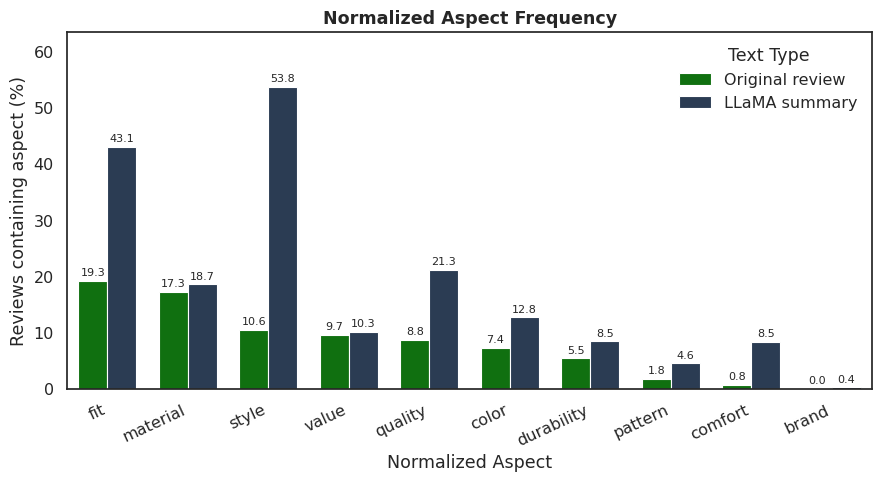

In [42]:
# 사전 정의 속성과 파생 속성만 선택
normalized_aspect_df = aspect_pair_df[
    aspect_pair_df['aspect_type'].isin([
        'Paper aspect',
        'Derived aspect'
    ])
].copy()

# 같은 리뷰에서 동일한 정규화 속성은 이미 한 행으로 정리되어 있음
aspect_frequency_df = normalized_aspect_df.groupby([
    'aspect',
    'aspect_type'
]).agg(
    review_count=(
        'review_aspect_raw',
        lambda value: value.notna().sum()
    ),
    summary_count=(
        'summary_aspect_raw',
        lambda value: value.notna().sum()
    )
).reset_index()

# 전체 분석 리뷰 수를 기준으로 속성 출현 비율 계산
total_review_count = analysis_df['source_index'].nunique()
aspect_frequency_long = aspect_frequency_df.melt(
    id_vars=['aspect', 'aspect_type'],
    value_vars=['review_count', 'summary_count'],
    var_name='text_type',
    value_name='count'
)
aspect_frequency_long['appearance_rate'] = (
    aspect_frequency_long['count']
    / total_review_count
    * 100
)
aspect_frequency_long['text_type'] = (
    aspect_frequency_long['text_type'].map({
        'review_count': 'Original review',
        'summary_count': 'LLaMA summary'
    })
)

# 원문 출현 빈도가 높은 순서로 속성 배치
aspect_order = (
    aspect_frequency_df.sort_values(
        'review_count',
        ascending=False
    )['aspect'].tolist()
)

plt.figure(figsize=(9, 5), facecolor='white')
ax = sns.barplot(
    data=aspect_frequency_long,
    x='aspect',
    y='appearance_rate',
    hue='text_type',
    order=aspect_order,
    palette={
        'Original review': '#008000',
        'LLaMA summary': '#243B5A'
    },
    width=0.72,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('Normalized Aspect Frequency', fontweight='bold')
ax.set_xlabel('Normalized Aspect')
ax.set_ylabel('Reviews containing aspect (%)')
ax.legend(title='Text Type', frameon=False)
ax.set_ylim(0, aspect_frequency_long['appearance_rate'].max() * 1.18)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f',
        padding=2,
        fontsize=8
    )

plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

논문 속성은 사전 정의된 5개 범주이며, 파생 속성은 JSON 규칙으로 통합한 범주이다. 규칙에 없는 표현은 추가 속성으로 유지한다. 비교 행을 합쳐 집계한 표는 보존 상태의 전체 규모를 보여주고, 원문·요약문별 표는 실제 출현 위치와 증가 또는 감소 방향을 보여준다. 두 표는 목적이 다르므로 함께 제시한다.

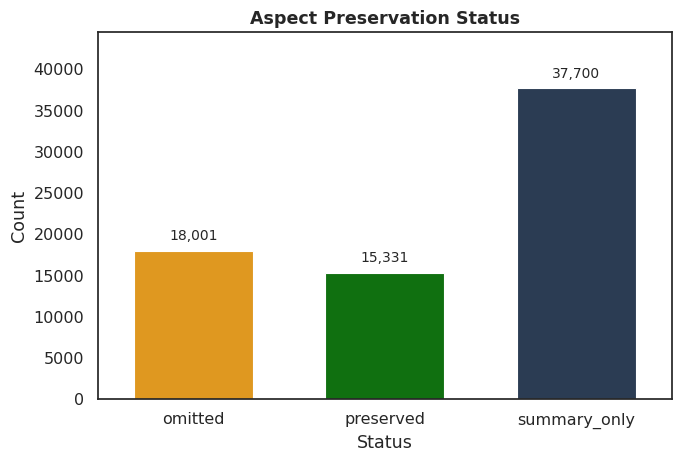

In [62]:
# 속성 보존 상태 시각화
status_plot = aspect_status.reset_index()
status_colors = {
    'preserved': '#008000',
    'omitted': '#FFA000',
    'summary_only': '#243B5A'
}

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=status_plot,
    x='status',
    y='count',
    hue='status',
    palette=status_colors,
    legend=False,
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('Aspect Preservation Status', fontweight='bold')
ax.set_xlabel('Status')
ax.set_ylabel('Count')
ax.set_ylim(0, status_plot['count'].max() * 1.18)

for index, row in status_plot.iterrows():
    ax.text(
        index,
        row['count'] + status_plot['count'].max() * 0.025,
        f"{int(row['count']):,}",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

원본에만 남은 속성이 많다면 요약 과정에서 세부 사용자 경험이 충분히 보존되지 않았을 가능성이 있다.

## PyABSA 통합 속성 감성 평가

속성 추출 시 함께 계산된 PyABSA의 부정·중립·긍정 라벨과 신뢰도를 재사용한다.
별도 감성 모델을 다시 실행하지 않아 속성-감성 대응을 유지하고 전체 실행 시간도 줄인다.

In [ ]:
# PyABSA 감성 라벨을 분석용 점수로 변환
aspect_pair_df['review_sentiment_score'] = (
    aspect_pair_df['review_sentiment'].apply(sentiment_to_score)
)
aspect_pair_df['summary_sentiment_score'] = (
    aspect_pair_df['summary_sentiment'].apply(sentiment_to_score)
)

sentiment_source_summary = pd.DataFrame({
    'setting': ['Model', 'Output', 'Score mapping'],
    'value': [
        'PyABSA ATEPC multilingual',
        'Aspect + sentiment + confidence',
        'Negative=-1, Neutral=0, Positive=1'
    ]
})

sentiment_source_summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,setting,value
0,Model,PyABSA ATEPC multilingual
1,Output,Aspect + sentiment + confidence
2,Score mapping,"Negative=-1, Neutral=0, Positive=1"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 원본과 요약문의 속성별 감성 결과 확인
sentiment_check = aspect_pair_df[[
    'source_index',
    'aspect',
    'review_aspect_raw',
    'review_sentiment',
    'review_confidence',
    'summary_aspect_raw',
    'summary_sentiment',
    'summary_confidence'
]].head(20)

sentiment_check

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,source_index,aspect,review_aspect_raw,review_sentiment,review_confidence,summary_aspect_raw,summary_sentiment,summary_confidence
0,63407,designs,designs,Positive,0.9778,designs,Positive,0.9848
1,63407,fit,fit,Positive,0.9456,size,Positive,0.9953
2,63407,value,price,Positive,0.9476,None,None,NaN
3,64144,style,None,None,NaN,design,Positive,0.9969
4,64144,value,None,None,NaN,value for money,Positive,0.9974
5,18896,clothing items,None,None,NaN,clothing items,Positive,0.9820
6,18896,comfort,None,None,NaN,comfort,Positive,0.9878
7,18896,jeans,jeans,Positive,0.5478,jeans,Positive,0.7458
8,18896,shorts,shorts,Positive,0.9952,shorts,Positive,0.9927
9,38719,durability,zipper,Positive,0.9683,None,None,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


위 표에서 추출 속성과 감성 라벨이 문맥에 맞는지 확인하고, 신뢰도가 낮은 사례는 수동 검토 대상으로 사용한다.

In [ ]:
# 신뢰도가 낮은 감성 결과를 수동 검토 후보로 정리
review_low_confidence = aspect_pair_df.loc[
    aspect_pair_df['review_confidence'].lt(0.8),
    ['source_index', 'aspect', 'review_aspect_raw',
     'review_sentiment', 'review_confidence']
].rename(columns={
    'review_aspect_raw': 'raw_aspect',
    'review_sentiment': 'sentiment',
    'review_confidence': 'confidence'
})
review_low_confidence['text_type'] = 'Original review'

summary_low_confidence = aspect_pair_df.loc[
    aspect_pair_df['summary_confidence'].lt(0.8),
    ['source_index', 'aspect', 'summary_aspect_raw',
     'summary_sentiment', 'summary_confidence']
].rename(columns={
    'summary_aspect_raw': 'raw_aspect',
    'summary_sentiment': 'sentiment',
    'summary_confidence': 'confidence'
})
summary_low_confidence['text_type'] = 'LLaMA summary'

low_confidence_sentiment_df = pd.concat(
    [review_low_confidence, summary_low_confidence],
    ignore_index=True
).sort_values('confidence')

low_confidence_sentiment_df.head(20)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,source_index,aspect,raw_aspect,sentiment,confidence,text_type
10509,13959,grip,grip,Positive,0.3380,LLaMA summary
11553,35043,earring,earring,Positive,0.3389,LLaMA summary
14012,20182,posts,posts,Neutral,0.3401,LLaMA summary
1575,62628,storage,storage,Neutral,0.3419,Original review
18401,61811,fits,fits,Negative,0.3436,LLaMA summary
10974,50403,fit,fit,Negative,0.3439,LLaMA summary
3877,26482,bead ones,bead ones,Neutral,0.3439,Original review
1466,8465,packaging,packaging,Neutral,0.3447,Original review
5647,26303,key ring,key ring,Negative,0.3451,Original review
3267,28516,material,fabric,Positive,0.3459,Original review


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 원본과 요약문의 감성 점수 차이 계산
aspect_pair_df['sentiment_shift'] = aspect_pair_df['summary_sentiment_score'] - aspect_pair_df['review_sentiment_score']

# 속성 보존 상태 확인
is_preserved = aspect_pair_df['status'] == 'preserved'
is_omitted = aspect_pair_df['status'] == 'omitted'
is_summary_only = aspect_pair_df['status'] == 'summary_only'

# 원본과 요약문의 감성 방향 확인
review_negative = aspect_pair_df['review_sentiment_score'] == -1
review_positive = aspect_pair_df['review_sentiment_score'] == 1
summary_negative = aspect_pair_df['summary_sentiment_score'] == -1
summary_positive = aspect_pair_df['summary_sentiment_score'] == 1

# 부정에서 긍정 또는 긍정에서 부정으로 바뀐 경우 확인
negative_to_positive = review_negative & summary_positive
positive_to_negative = review_positive & summary_negative
aspect_pair_df['sentiment_flip'] = is_preserved & (negative_to_positive | positive_to_negative)

# 부정 속성 누락과 요약문 단독 속성 확인
aspect_pair_df['negative_aspect_omitted'] = is_omitted & review_negative
aspect_pair_df['summary_only_candidate'] = is_summary_only

# 분석 결과를 하나의 표로 정리
sentiment_summary = pd.DataFrame({
    'measure': [
        'Preserved aspects',
        'Sentiment flips',
        'Negative aspects omitted',
        'Summary-only candidates'
    ],
    'count': [
        aspect_pair_df['status'].eq('preserved').sum(),
        aspect_pair_df['sentiment_flip'].sum(),
        aspect_pair_df['negative_aspect_omitted'].sum(),
        aspect_pair_df['summary_only_candidate'].sum()
    ]
})

sentiment_summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,measure,count
0,Preserved aspects,14070
1,Sentiment flips,944
2,Negative aspects omitted,1874
3,Summary-only candidates,40574


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


| 분석 항목 | 판정 조건 | 의미 |
|---|---|---|
| 속성 보존 | 원문과 요약문에 같은 속성이 존재 | 원문의 속성 정보가 유지된 경우이다. |
| 감성 반전 | 보존된 속성이 부정에서 긍정 또는 긍정에서 부정으로 변화 | 사용자의 선호 방향이 반대로 전달된 경우이다. |
| 부정 속성 누락 | 원문의 부정 속성이 요약문에서 사라짐 | 불만 정보가 요약 과정에서 제거된 경우이다. |
| 요약문 단독 속성 | 요약문에만 속성이 존재 | 표현 차이, 정보 추가 또는 환각 가능성이 있는 후보이다. |

감성 반전과 부정 속성 누락은 요약 과정의 문제로 볼 수 있지만, 요약문에만 있는 속성은 수동 확인 전까지 환각 후보로만 해석한다.

In [ ]:
# 중간 결과 저장
aspect_sentiment_path = Path(
    f'/content/drive/MyDrive/MAS_Rec/aspect_sentiment_{analysis_tag}.pkl'
)
aspect_pair_df.to_pickle(aspect_sentiment_path)

## 텍스트 오류와 평점 예측 오차의 관계

각 리뷰에 감성 반전·부정 속성 누락·요약문 단독 속성이 존재하는지 정리하고 MAE를 비교한다.

In [41]:
aspect_pair_df = pd.read_pickle('/content/drive/MyDrive/MAS_Rec/aspect_sentiment_full_test_len512.pkl')

In [ ]:
# 리뷰 단위 텍스트 오류 요약
review_issue_df = aspect_pair_df.groupby('source_index').agg(
    review_aspect_count=('review_aspect_raw', 'count'),
    summary_aspect_count=('summary_aspect_raw', 'count'),
    omitted_aspect_count=('status', lambda value: value.eq('omitted').sum()),
    has_sentiment_flip=('sentiment_flip', 'any'),
    has_negative_omission=('negative_aspect_omitted', 'any'),
    has_summary_only_candidate=('summary_only_candidate', 'any')
).reset_index()

analysis_result_df = analysis_df.merge(
    review_issue_df,
    on='source_index',
    how='left',
    validate='one_to_one'
)

count_columns = [
    'review_aspect_count',
    'summary_aspect_count',
    'omitted_aspect_count'
]
flag_columns = [
    'has_sentiment_flip',
    'has_negative_omission',
    'has_summary_only_candidate'
]

analysis_result_df[count_columns] = (
    analysis_result_df[count_columns].fillna(0).astype(int)
)
analysis_result_df[flag_columns] = (
    analysis_result_df[flag_columns].fillna(False).astype(bool)
)
analysis_result_df['error_group'] = np.select(
    [
        analysis_result_df['absolute_error'].ge(1.0),
        analysis_result_df['absolute_error'].le(0.25)
    ],
    ['Large error', 'Small error'],
    default='Middle error'
)
analysis_result_df['review_length'] = (
    analysis_result_df['text'].fillna('').str.split().str.len()
)

error_group_summary = analysis_result_df.groupby('error_group').agg(
    count=('absolute_error', 'size'),
    mae=('absolute_error', 'mean'),
    sentiment_flip_rate=('has_sentiment_flip', 'mean'),
    negative_omission_rate=('has_negative_omission', 'mean'),
    summary_only_candidate_rate=('has_summary_only_candidate', 'mean')
).round(4)

error_group_summary

/tmp/ipykernel_915/277487713.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  analysis_result_df[flag_columns].fillna(False).astype(bool)


,count,mae,sentiment_flip_rate,negative_omission_rate,summary_only_candidate_rate
error_group,,,,,
Large error,1036,1.3230,0.1197,0.2394,0.9527
Middle error,3768,0.5795,0.1152,0.1839,0.9522
Small error,8540,0.0960,0.0306,0.0518,0.9536


큰 오류군에서 감성 반전이나 부정 속성 누락 비율이 높다면 텍스트 요약 오류와 평점 예측 오차가 함께 나타나는 경향이 있다고 해석할 수 있다.

In [ ]:
# 텍스트 문제 유무에 따른 MAE
issue_names = {
    'has_sentiment_flip': 'Sentiment flip',
    'has_negative_omission': 'Negative omission',
    'has_summary_only_candidate': 'Summary-only aspect'
}

issue_rows = []

for column, label in issue_names.items():
    for has_issue, group in analysis_result_df.groupby(column):
        issue_rows.append({
            'issue': label,
            'has_issue': bool(has_issue),
            'count': len(group),
            'mae': group['absolute_error'].mean(),
            'large_error_rate': group['absolute_error'].ge(1.0).mean()
        })

issue_comparison = pd.DataFrame(issue_rows).round(4)
issue_comparison

,issue,has_issue,count,mae,large_error_rate
0,Sentiment flip,False,12525,0.3143,0.0728
1,Sentiment flip,True,819,0.5337,0.1514
2,Negative omission,False,11961,0.2983,0.0659
3,Negative omission,True,1383,0.5831,0.1793
4,Summary-only aspect,False,625,0.3436,0.0784
5,Summary-only aspect,True,12719,0.3270,0.0776


각 문제의 발생 여부에 따라 MAE와 큰 오류 비율이 실제로 달라지는지 표로 확인한다.

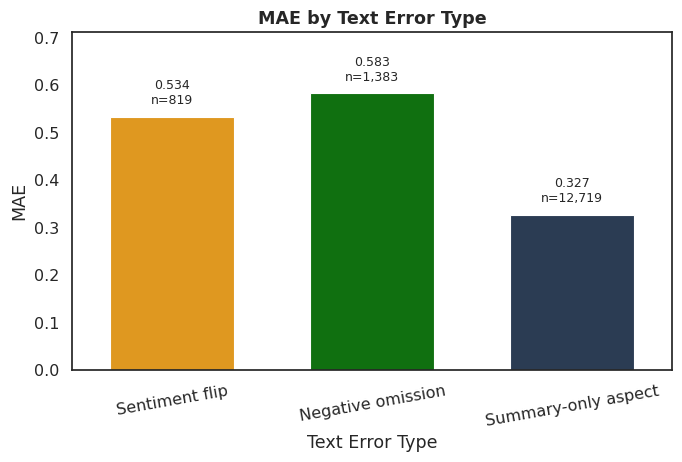

In [ ]:
# 텍스트 문제가 있는 사례의 MAE
issue_plot = issue_comparison[issue_comparison['has_issue']].copy()
issue_colors = ['#FFA000', '#008000', '#243B5A']

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=issue_plot,
    x='issue',
    y='mae',
    hue='issue',
    palette=issue_colors,
    legend=False,
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('MAE by Text Error Type', fontweight='bold')
ax.set_xlabel('Text Error Type')
ax.set_ylabel('MAE')
ax.set_ylim(0, issue_plot['mae'].max() * 1.22)

for index, row in issue_plot.reset_index(drop=True).iterrows():
    ax.text(
        index,
        row['mae'] + issue_plot['mae'].max() * 0.035,
        f"{row['mae']:.3f}\nn={int(row['count']):,}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

감성 반전과 부정 속성 누락이 확인된 사례는 해당 문제가 없는 사례보다 높은 MAE와 큰 오류 비율을 보였다. 이는 요약 과정에서 사용자의 감성 방향이 변경되거나 핵심 불만이 제거되는 현상이 높은 추천 오차와 관련될 가능성을 보여준다.

반면 요약문 단독 속성의 존재 여부에 따른 성능 차이는 뚜렷하지 않았다. 다만 의미가 같은 서로 다른 표현이 단독 속성으로 분류되었을 가능성이 있으므로, 현재의 정규화 기준에서 유의미한 관계가 발견되지 않은 것으로 해석한다. 모든 결과는 인과관계가 아니라 텍스트 오류와 예측 오차 사이의 연관성을 나타낸다.

## 대표 사례 확인

자동 분석으로 찾은 큰 오류 사례를 원문과 직접 비교해 근거 없는 내용, 감성 반전, 핵심 불만 누락을 확인한다.

In [ ]:
# 자동 분석으로 찾은 대표 사례
representative_cases = analysis_result_df[
    analysis_result_df['absolute_error'].ge(1.0)
    & (
        analysis_result_df['has_sentiment_flip']
        | analysis_result_df['has_negative_omission']
        | analysis_result_df['has_summary_only_candidate']
    )
].sort_values('absolute_error', ascending=False).head(10)[[
    'rating',
    'prediction',
    'absolute_error',
    'has_sentiment_flip',
    'has_negative_omission',
    'has_summary_only_candidate',
    'text',
    'LLaMA_Output'
]].copy()

representative_cases['prediction'] = representative_cases['prediction'].round(3)
representative_cases['absolute_error'] = representative_cases['absolute_error'].round(3)
representative_cases['text'] = (
    representative_cases['text'].str.slice(0, 180) + '...'
)
representative_cases['LLaMA_Output'] = (
    representative_cases['LLaMA_Output'].str.slice(0, 180) + '...'
)

representative_cases.reset_index(drop=True)

,rating,prediction,absolute_error,has_sentiment_flip,has_negative_omission,has_summary_only_candidate,text,LLaMA_Output
0,1,4.707,3.707,False,False,True,Would have enjoyed reviewing this product beca...,This user had a very positive experience with ...
1,1,4.641,3.641,False,False,True,[[VIDEOID:8d744c5ebafdff63f2e0e27406a9872a]] T...,"Based on the user review, here is a summary of..."
2,1,4.634,3.634,False,True,True,This is two pieces of aluminum held together w...,"I'm not sure what kind of product this is, but..."
3,1,4.630,3.630,False,True,True,The photos make this product seem like a high ...,"Based on this review, it seems that the user i..."
4,1,4.516,3.516,False,False,True,Update. Wore these on and off for about 2 wee...,"Based on the user reviews, here is a summary o..."
5,2,5.085,3.085,False,True,False,I did not expect these glasses to be this flim...,This review suggests that the user is very ple...
6,5,1.924,3.076,False,True,True,"Holy Cow! These are ""made in china!"" (see imag...","Based on this review, it appears that the user..."
7,2,4.995,2.995,False,True,True,The Minimalist Mens Wallet with Money Clip can...,"Based on this review, it appears that the user..."
8,2,4.939,2.939,False,True,False,"These are sold as ""Men's Athletic Socks."" The ...","Based on this review, it..."
9,1,3.918,2.918,False,False,True,I thought they would be bigger<br />Way too ti...,"Based on the user's review, it appears that th..."


대표 사례에서는 자동 라벨보다 원문에 실제 근거가 있는지를 우선 확인한다.

In [ ]:
# 같은 평점 안에서 큰 오류와 비슷한 작은 오류 사례 연결
MANUAL_CASES_PER_RATING = 10
manual_rows = []
pair_id = 0

for rating, rating_df in analysis_result_df.groupby('rating'):
    large_cases = rating_df[
        rating_df['absolute_error'].ge(1.0)
    ].nlargest(MANUAL_CASES_PER_RATING, 'absolute_error')

    small_pool = rating_df[
        rating_df['absolute_error'].le(0.25)
    ].copy()

    for _, large_case in large_cases.iterrows():
        pair_id += 1
        large_row = large_case.to_dict()
        large_row['matched_pair_id'] = pair_id
        large_row['sample_group'] = 'large_error'
        manual_rows.append(large_row)

        if small_pool.empty:
            continue

        length_scale = small_pool['review_length'].std()
        user_scale = small_pool['user_interactions'].std()
        item_scale = small_pool['item_interactions'].std()

        length_scale = length_scale if pd.notna(length_scale) and length_scale > 0 else 1
        user_scale = user_scale if pd.notna(user_scale) and user_scale > 0 else 1
        item_scale = item_scale if pd.notna(item_scale) and item_scale > 0 else 1

        match_distance = (
            (small_pool['review_length'] - large_case['review_length']).abs()
            / length_scale
            + (small_pool['user_interactions'] - large_case['user_interactions']).abs()
            / user_scale
            + (small_pool['item_interactions'] - large_case['item_interactions']).abs()
            / item_scale
        )

        matched_index = match_distance.idxmin()
        matched_row = small_pool.loc[matched_index].to_dict()
        matched_row['matched_pair_id'] = pair_id
        matched_row['sample_group'] = 'small_error'
        manual_rows.append(matched_row)
        small_pool = small_pool.drop(index=matched_index)

manual_sample = pd.DataFrame(manual_rows)[[
    'source_index',
    'matched_pair_id',
    'sample_group',
    'rating',
    'prediction',
    'absolute_error',
    'text',
    'LLaMA_Output'
]].copy()

manual_sample['unsupported_claim'] = pd.NA
manual_sample['sentiment_hallucination'] = pd.NA
manual_sample['complaint_omitted'] = pd.NA
manual_sample['note'] = ''

manual_sample_path = Path(
    f'/content/drive/MyDrive/MAS_Rec/manual_text_error_{analysis_tag}.csv'
)

# 이미 작성한 GPT-5.6-Sol Medium 1차 판정 파일은 덮어쓰지 않음
if not manual_sample_path.exists():
    manual_sample.to_csv(manual_sample_path, index=False)

manual_sample.groupby(['rating', 'sample_group']).size().unstack(fill_value=0)

sample_group,large_error,small_error
rating,,
1,10,6
2,10,10
3,10,10
4,10,10
5,10,10


| 평가 항목 | 판정 기준 |
|---|---|
| 근거 없는 주장 | 원문이 뒷받침하지 않는 구체적인 내용이 요약문에 추가된 경우이다. |
| 감성 왜곡 | 원문의 전반적인 감성이나 속성에 대한 평가가 반대로 표현되거나 약화된 경우이다. |
| 불만 누락 | 원문의 핵심 불만 또는 부정적 속성이 요약문에서 제거되거나 약화된 경우이다. |
| 판정 근거 | 각 사례의 판정 이유를 `note`에 한 문장으로 기록한다. |

GPT-5.6-Sol Medium이 96개의 원문 리뷰와 LLaMA 요약문을 개별적으로 비교하여 `unsupported_claim`, `sentiment_hallucination`, `complaint_omitted`를 0 또는 1로 1차 판정하였다. 각 오류 항목은 동시에 발생할 수 있으므로 오류 건수의 합은 전체 표본 수와 일치하지 않을 수 있다.

**용어 구분:** 감성 반전(Sentiment flip)은 동일한 속성에 대한 PyABSA 감성 라벨이 긍정에서 부정 또는 부정에서 긍정으로 바뀐 경우를 코드로 판정한 결과이다. 감성 왜곡(Sentiment distortion)은 GPT-5.6-Sol Medium이 원문과 요약문을 직접 비교하여 감성 반전뿐 아니라 부정 표현의 약화와 과도한 긍정화를 포함해 판정한 결과이다. 따라서 감성 반전은 감성 왜곡의 일부에 해당할 수 있으나 두 지표는 동일하지 않다.


## GPT-5.6-Sol Medium 기반 사례 판정 결과

평점별로 큰 오류와 작은 오류 사례를 대응하여 추출하였으며, 평점 1의 작은 오류 후보가 부족하여 최종 96개 사례를 구성하였다. GPT-5.6-Sol Medium이 각 사례의 원문 리뷰와 LLaMA 요약문을 비교하여 세 가지 오류 항목을 1차 판정하였다. 이 결과는 연구자의 독립적인 수동 판정이 아니므로 경계 사례에는 추가 검토가 필요하다.

| 표본 | 기준 | 사례 수 |
|---|---|---:|
| 큰 오류 | 절대오차 1.0 이상 | 50 |
| 작은 오류 | 절대오차 0.25 이하 | 46 |
| 전체 | 평점별 대응 표본 | 96 |


In [ ]:
# GPT-5.6-Sol Medium 1차 판정 결과 정량화
manual_checked = pd.read_csv(manual_sample_path)
annotation_columns = [
    'unsupported_claim',
    'sentiment_hallucination',
    'complaint_omitted'
]

for column in annotation_columns:
    manual_checked[column] = pd.to_numeric(
        manual_checked[column],
        errors='coerce'
    )

manual_completed = manual_checked.dropna(
    subset=annotation_columns,
    how='all'
)

if manual_completed.empty:
    manual_annotation_summary = pd.DataFrame({
        'status': ['GPT-5.6-Sol Medium 1차 판정 CSV를 먼저 준비해 주세요.']
    })
else:
    manual_annotation_summary = manual_completed.groupby(
        'sample_group'
    ).agg(
        reviewed_cases=('source_index', 'size'),
        unsupported_claim_rate=('unsupported_claim', 'mean'),
        sentiment_hallucination_rate=('sentiment_hallucination', 'mean'),
        complaint_omission_rate=('complaint_omitted', 'mean'),
        mae=('absolute_error', 'mean')
    ).round(4)

manual_annotation_summary

,reviewed_cases,unsupported_claim_rate,sentiment_hallucination_rate,complaint_omission_rate,mae
sample_group,,,,,
large_error,50,0.4800,0.2200,0.4200,2.5280
small_error,46,0.2391,0.0217,0.0217,0.1345


| 표본 | 사례 수 | 근거 없는 주장 | 감성 왜곡 | 불만 누락 | 하나 이상 해당 |
|---|---:|---:|---:|---:|---:|
| 큰 오류 | 50 | 24 | 11 | 21 | 27 |
| 작은 오류 | 46 | 11 | 1 | 1 | 11 |
| 전체 | 96 | 35 | 12 | 22 | 38 |

큰 오류군에서는 감성 왜곡과 불만 누락이 작은 오류군보다 빈번하게 나타났다. 근거 없는 주장도 큰 오류군에서 더 많이 확인되었으나, 작은 오류군에서도 일부 관찰되었으므로 근거 없는 정보의 존재만으로 예측 오차를 설명하기는 어렵다. 본 결과는 GPT-5.6-Sol Medium을 이용한 보조적 1차 판정이며, 논문에 활용할 때에는 연구자가 경계 사례를 재검토해야 한다.


## 결론

1. 원본 리뷰의 속성별 감성이 요약문에서 반대로 변한 경우 높은 예측 오차와 연관되는 경향이 나타났다.
2. 원본 리뷰의 부정적 속성이 요약문에서 누락된 경우에도 MAE와 큰 오류 비율이 상대적으로 높게 나타났다.
3. 요약문에만 나타난 속성은 추천 성능과 뚜렷한 관계를 보이지 않았다.
4. 단순한 속성 개수보다 감성 방향과 부정적 선호 정보의 보존이 추천 성능에 더 중요한 것으로 나타났다.
5. LLM 요약문의 의미 보존 여부는 멀티모달 추천 시스템의 예측 결과를 설명하는 주요 분석 요소로 활용할 수 있다.

## 한계점

1. 텍스트 모달리티를 중심으로 분석하여 LLaVA가 처리한 이미지 정보의 오류와 추천 성능 간의 관계를 동일한 기준으로 검증하지 못하였다.
2. 규칙 기반 속성 정규화로 인해 의미가 같은 서로 다른 표현이 별개의 속성으로 분류되었을 가능성이 있다.
3. 감성 반전은 긍정과 부정의 직접적인 전환만 포함하므로 중립 감성과 관련된 변화를 충분히 반영하지 못하였다.
4. GPT-5.6-Sol Medium 기반 사례 판정은 전체 데이터가 아닌 96개 표본을 대상으로 수행되었으며, 연구자 간 일치도나 독립적인 사람 평가를 포함하지 않아 결과의 일반화에 한계가 있다.
5. 분석 결과는 텍스트 오류와 예측 오차 사이의 연관성을 보여주지만 직접적인 인과관계를 입증하지는 못하였다.